# Baseline figures for the FJSP report

This notebook regenerates the report's **makespan-gap box plots**, **problem illustration**, and **aligned Gantt comparison**. It reads the committed `.fjs` instances, CP-SAT JSON references, and baseline CSV/JSONL results. The Gantt cell reruns GA, BRKGA, NSGA-II, and MOEA/D for one illustrative instance because their full schedules were not saved in the CSVs. It writes PNG and PDF files to `figures/`. If the installed `pymoo` reproduces different schedules than the archived seed-0 CSVs, the Gantt cell reports the difference. Its two-column figure has a separate filename, preserving the original.

Run from the repository root or from `notebooks/` after installing `requirements.txt` and Jupyter. The Gantt cell uses the same 1,000-evaluation budget and seed 0 as the report. The DANIEL and Song Gantt schedules are read from their saved JSONL files; the notebook does not load the neural models.

In [1]:
from pathlib import Path
import csv, hashlib, json, os, sys
from statistics import mean, median
import matplotlib.pyplot as plt
from matplotlib.patches import Patch

# Run from the repository root or from notebooks/.
ROOT = Path.cwd().resolve()
if not (ROOT / "data").is_dir():
    ROOT = ROOT.parent
if not (ROOT / "data").is_dir() or not (ROOT / "baselines").is_dir():
    raise FileNotFoundError("Open this notebook from the repository or notebooks/ directory")
os.chdir(ROOT)  # baseline seed helpers resolve data/ relative to the working directory
sys.path.insert(0, str(ROOT))
(ROOT / "figures").mkdir(exist_ok=True)

from baselines.common import dispatch, read_fjs, validate_schedule


## Dataset-wide comparison and box plots

Each stochastic method contributes one mean gap per instance across its saved seeds. Ours (priority-first) and Ours (non-delay) use the mean of the 16 samples in `runs/machine_priority_10x5`; the Ours-Top16 rows use the lowest of those 16. DANIEL-Top16 and Song-Top16 use the lowest of 16 samples of those policies. Rows are grouped into PDRs, evolutionary algorithms, learned methods, and learned methods with sampling. The dashed line is the CP-SAT reference.

Mean makespan gap (%) to CP-SAT; lower is better
Method                              Original 8×4       Original 10×5            SD1 10×5            SD2 10×5         Brandimarte
FIFO                                       23.00               23.15               20.18               29.44               15.61
MOR                                        22.94               24.41               20.49               29.68               15.97
MWKR                                       21.36               23.35               19.91               35.01               15.68
Random                                     52.08               54.89               53.25               64.73               54.70
GA                                         12.41               16.31               13.85               18.52               13.09
BRKGA                                      11.57               14.75               12.92               18.19               12.67
NSGA-II                                    11.24

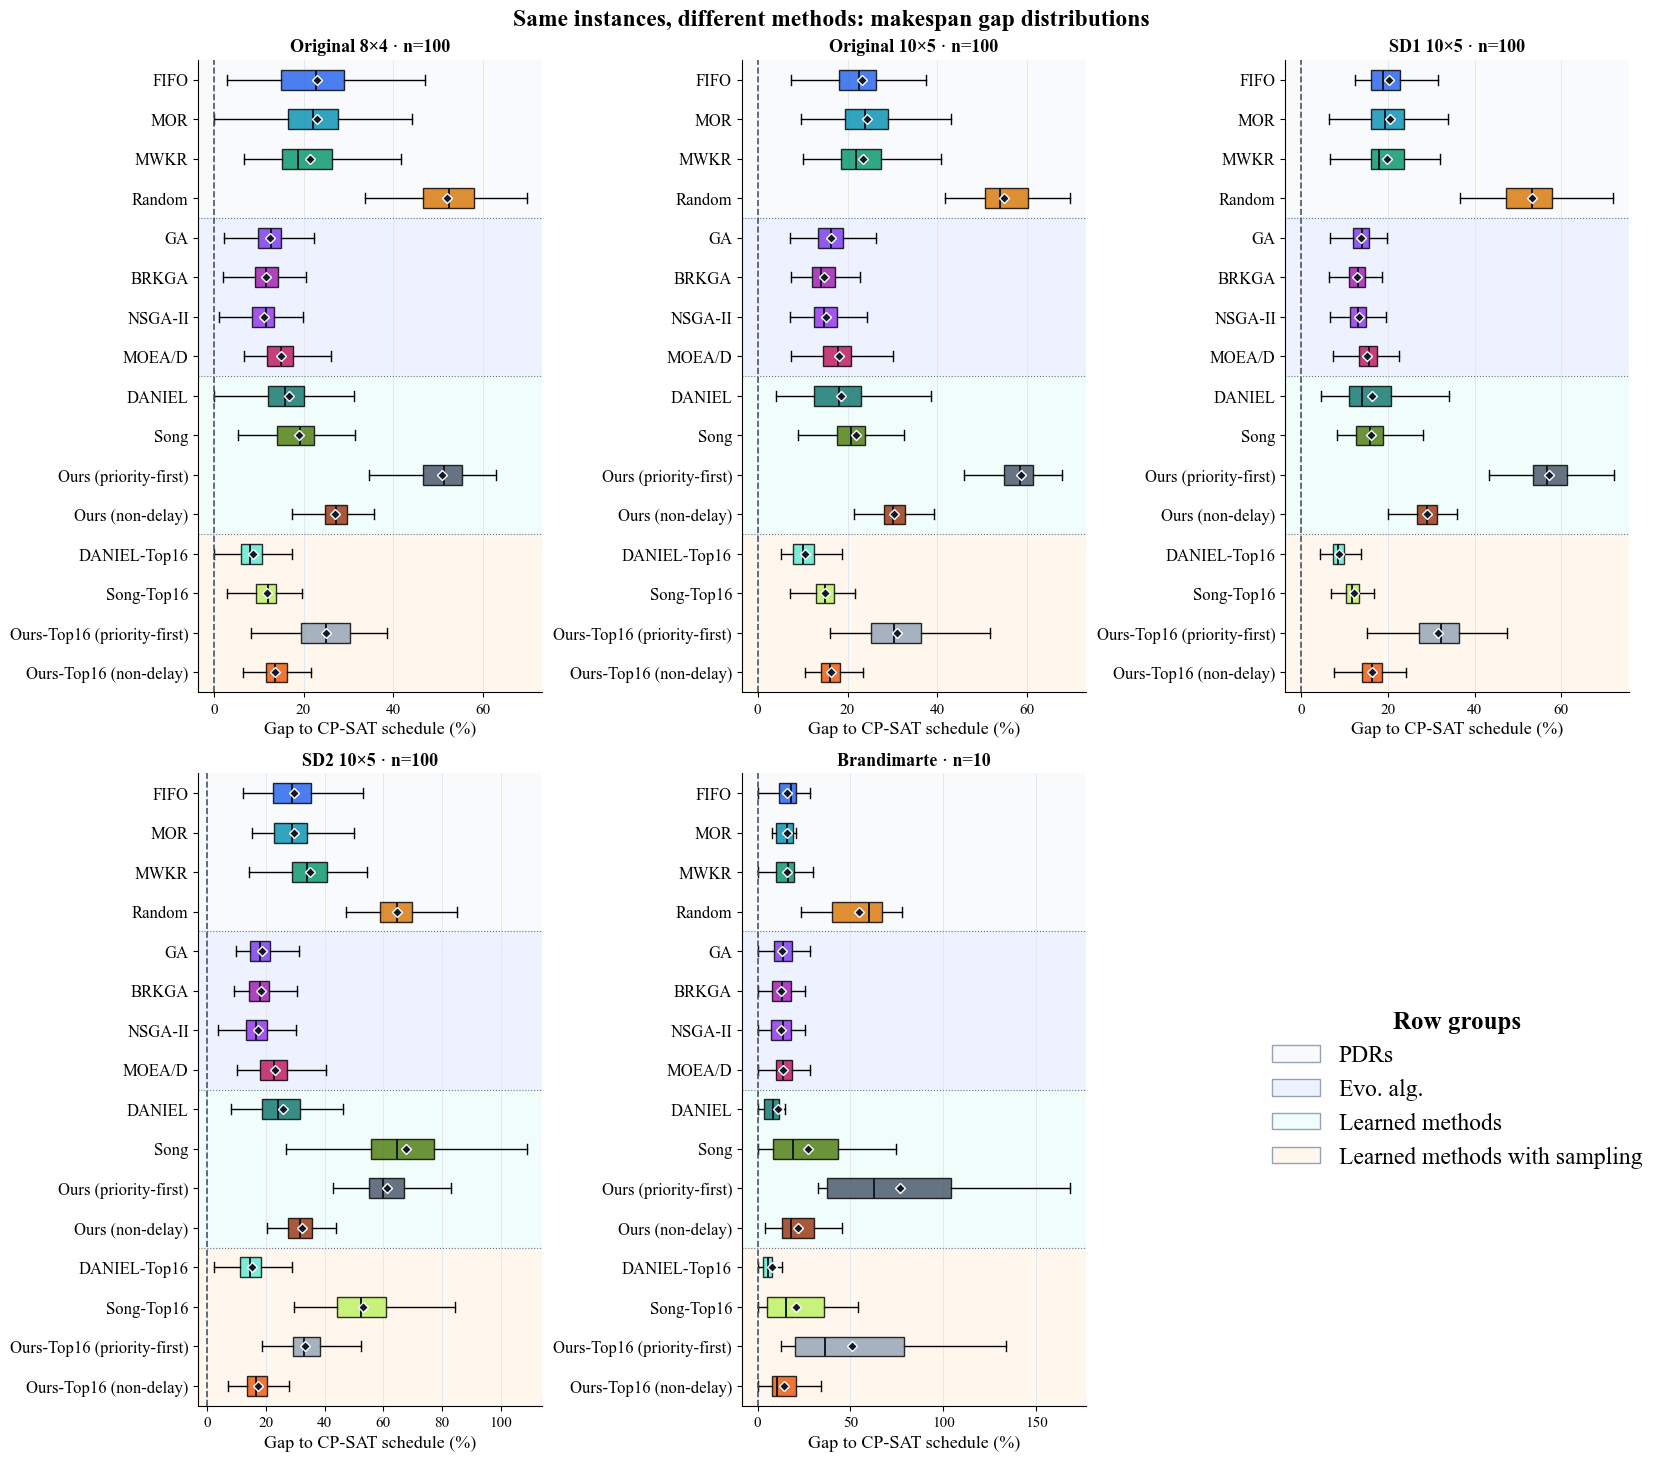

In [18]:
DATASETS = [
    ("Original 8×4", "SD_original/8x4/test", "8x4_test"),
    ("Original 10×5", "SD_original/10x5/test", "10x5_test"),
    ("SD1 10×5", "SD1_lit/10x5", "sd1_10x5"),
    ("SD2 10×5", "SD2_lit/10x5+mix", "sd2_10x5"),
    ("Brandimarte", "BenchData/Brandimarte", "brandimarte"),
]
GROUPS = [
    ("PDRs", ["FIFO", "MOR", "MWKR", "Random"]),
    ("Evo. alg.", ["GA", "BRKGA", "NSGA-II", "MOEA/D"]),
    ("Learned methods", ["DANIEL", "Song", "Ours (priority-first)", "Ours (non-delay)"]),
    ("Learned methods with sampling", [
        "DANIEL-Top16", "Song-Top16",
        "Ours-Top16 (priority-first)", "Ours-Top16 (non-delay)",
    ]),
]
METHODS = [method for _, methods in GROUPS for method in methods]
GROUP_SHADES = ["#f8fafc", "#eef2ff", "#f0fdfa", "#fff7ed"]
SEEDS = {"GA": 3, "BRKGA": 3, "NSGA-II": 3, "MOEA/D": 3, "Random": 5}
FILES = {"NSGA-II": "nsga2", "MOEA/D": "moead"}
OURS = {"Ours (priority-first)": "current_mean",
        "Ours-Top16 (priority-first)": "current_best",
        "Ours (non-delay)": "nondelay_mean",
        "Ours-Top16 (non-delay)": "nondelay_best"}
SAMPLED = {"DANIEL-Top16": ("daniel", "makespan_best"),
           "Song-Top16": ("song", "makespan_best")}
COLORS = {"FIFO": "#2563eb", "MOR": "#0891b2", "MWKR": "#059669",
          "GA": "#7c3aed", "BRKGA": "#a21caf", "NSGA-II": "#9333ea",
          "MOEA/D": "#be185d", "DANIEL": "#0f766e", "DANIEL-Top16": "#5eead4",
          "Song": "#4d7c0f", "Song-Top16": "#bef264",
          "Ours (priority-first)": "#475569", "Ours-Top16 (priority-first)": "#94a3b8",
          "Ours (non-delay)": "#9a3412", "Ours-Top16 (non-delay)": "#ea580c",
          "Random": "#d97706"}

def load_rows(path):
    with path.open(newline="") as stream:
        return {Path(row["instance"]).as_posix(): row for row in csv.DictReader(stream)}

def load_our_rows(data_path):
    path = ROOT / "runs/machine_priority_10x5/eval" / (data_path.replace("/", "__") + ".csv")
    with path.open(newline="") as stream:
        return {row["instance"]: row for row in csv.DictReader(stream)}

def load_sample_rows(name, tag):
    path = ROOT / "baselines/results" / f"{name}_{tag}_sample16.csv"
    with path.open(newline="") as stream:
        return {row["instance"]: row for row in csv.DictReader(stream)}

def collect(label, data_path, tag):
    folder = ROOT / "data" / data_path
    instances = sorted(folder.glob("*.fjs"))
    keys = [path.relative_to(ROOT).as_posix() for path in instances]
    references = {}
    for path, key in zip(instances, keys):
        result = json.loads((ROOT / "CP-SAT" / data_path / f"{path.stem}.json").read_text())
        validate_schedule(read_fjs(path), result)
        references[key] = result
    out = {"label": label, "n": len(keys), "methods": {}}
    for method in METHODS:
        if method in SAMPLED:
            name, column = SAMPLED[method]
            rows = load_sample_rows(name, tag)
            if any(key not in rows for key in keys):
                raise ValueError(f"Mismatched instances for {method} on {label}")
            if any(rows[key]["feasible"] != "True" for key in keys):
                raise ValueError(f"Infeasible result for {method} on {label}")
            gaps = [100 * (float(rows[key][column]) / references[key]["makespan"] - 1)
                    for key in keys]
            out["methods"][method] = {"gaps": gaps, "mean_gap": mean(gaps)}
            continue
        if method in OURS:
            rows = load_our_rows(data_path)
            column = OURS[method]
            feasible = column.split("_")[0] + "_feasible"
            if any(Path(key).stem not in rows for key in keys):
                raise ValueError(f"Mismatched instances for {method} on {label}")
            if any(rows[Path(key).stem][feasible] != "True" for key in keys):
                raise ValueError(f"Infeasible result for {method} on {label}")
            gaps = [100 * (float(rows[Path(key).stem][column]) / references[key]["makespan"] - 1)
                    for key in keys]
            out["methods"][method] = {"gaps": gaps, "mean_gap": mean(gaps)}
            continue
        name = FILES.get(method, method.lower())
        paths = ([ROOT / "baselines/results" / f"{name}_{tag}.csv"] if method not in SEEDS
                 else [ROOT / "baselines/results" / f"{name}_{tag}_seed{s}.csv"
                       for s in range(SEEDS[method])])
        runs = [load_rows(path) for path in paths]
        if any(set(run) != set(keys) for run in runs):
            raise ValueError(f"Mismatched instances for {method} on {label}")
        if any(run[key]["feasible"] != "True" for run in runs for key in keys):
            raise ValueError(f"Infeasible result for {method} on {label}")
        gaps = [100 * (mean(int(run[key]["makespan"]) for run in runs)
                       / references[key]["makespan"] - 1) for key in keys]
        out["methods"][method] = {"gaps": gaps, "mean_gap": mean(gaps)}
    return out

def draw_boxplots(results):
    previous_font = plt.rcParams["font.family"]
    plt.rcParams["font.family"] = "Times New Roman"
    fig, axes = plt.subplots(2, 3, figsize=(16.5, 14.5), layout="constrained")
    spans = []
    start = 1
    for (name, methods), shade in zip(GROUPS, GROUP_SHADES):
        stop = start + len(methods) - 1
        spans.append((name, start, stop, shade))
        start = stop + 1
    for ax, result in zip(axes.flat, results):
        data = [result["methods"][method]["gaps"] for method in METHODS]
        box = ax.boxplot(data, orientation="horizontal", patch_artist=True, showmeans=True,
                         showfliers=False,
                         meanprops={"marker": "D", "markerfacecolor": "#111827",
                                    "markeredgecolor": "white", "markersize": 5},
                         medianprops={"color": "#111827", "linewidth": 1.4})
        for patch, method in zip(box["boxes"], METHODS):
            patch.set_facecolor(COLORS[method])
            patch.set_alpha(0.82)
        for name, start, stop, shade in spans:
            ax.axhspan(start - 0.5, stop + 0.5, color=shade, zorder=0)
            if start > 1:
                ax.axhline(start - 0.5, color="#64748b", linewidth=0.8, linestyle=":")
        ax.set_yticks(range(1, len(METHODS) + 1), METHODS)
        ax.tick_params(axis="y", labelsize=12)
        ax.tick_params(axis="x", labelsize=11)
        ax.invert_yaxis()
        ax.axvline(0, color="#475569", linestyle="--", linewidth=1.2)
        ax.set_title(f"{result['label']} · n={result['n']}", fontsize=13, fontweight="bold")
        ax.set_xlabel("Gap to CP-SAT schedule (%)", fontsize=13)
        ax.grid(axis="x", color="#e2e8f0", linewidth=0.7)
        ax.set_axisbelow(True)
        for spine in ("top", "right"):
            ax.spines[spine].set_visible(False)
    legend_ax = axes.flat[-1]
    legend_ax.axis("off")
    legend_ax.legend(
        handles=[Patch(facecolor=shade, edgecolor="#94a3b8", label=name)
                 for (name, _), shade in zip(GROUPS, GROUP_SHADES)],
        loc="center", frameon=False, fontsize=17, title="Row groups",
        title_fontproperties={"weight": "bold", "size": 18},
    )
    fig.suptitle("Same instances, different methods: makespan gap distributions",
                 fontsize=17, fontweight="bold")
    path = ROOT / "figures/all_methods_gap_boxplots.png"
    fig.savefig(path, dpi=220, bbox_inches="tight", facecolor="white")
    fig.savefig(path.with_suffix(".pdf"), bbox_inches="tight", facecolor="white")
    print(f"Saved {path} and PDF")
    plt.rcParams["font.family"] = previous_font

results = [collect(*dataset) for dataset in DATASETS]
print("Mean makespan gap (%) to CP-SAT; lower is better")
print(f"{'Method':<28}" + ''.join(f"{r['label']:>20}" for r in results))
for method in METHODS:
    print(f"{method:<28}" + ''.join(f"{r['methods'][method]['mean_gap']:>20.2f}" for r in results))
draw_boxplots(results)


## Problem illustration

The left panel shows eligible machines and processing times; the right panel shows the CP-SAT schedule for the same instance.

Saved C:\Users\mnapo\Desktop\IDL_Project\figures\fjsp_problem_example.png and C:\Users\mnapo\Desktop\IDL_Project\figures\fjsp_problem_example.pdf


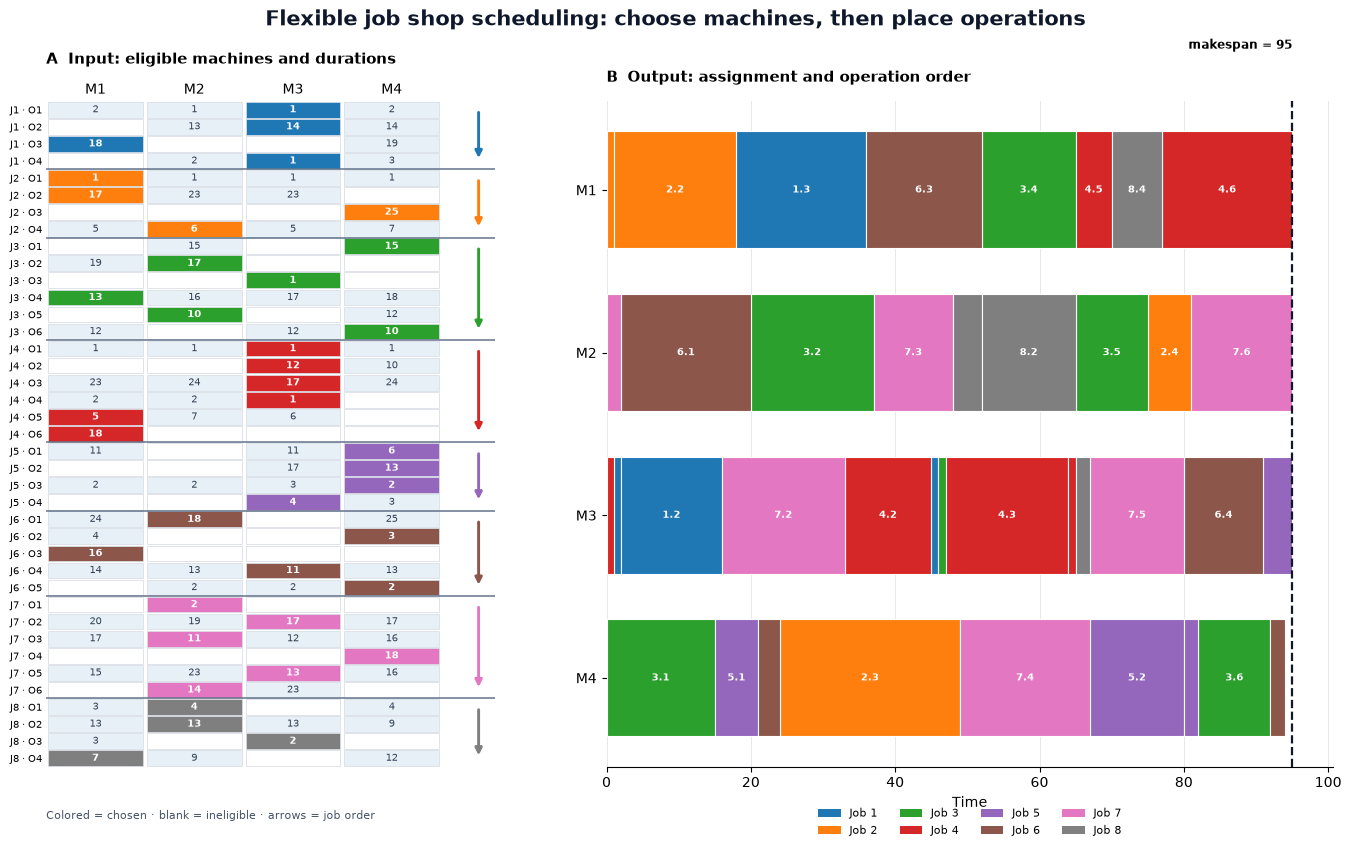

In [3]:
def draw(instance, result, output):
    validate_schedule(instance, result)
    jobs = instance["jobs"]
    n_machines = instance["n_machines"]
    operations = [(j, k, options) for j, job in enumerate(jobs) for k, options in enumerate(job)]
    colors = plt.get_cmap("tab10").colors
    fig = plt.figure(figsize=(13.4, 8.4), layout="constrained")
    grid = fig.add_gridspec(1, 2, width_ratios=(1.02, 1.65), wspace=0.12)
    ax_input = fig.add_subplot(grid[0, 0])
    ax_schedule = fig.add_subplot(grid[0, 1])

    # Left: eligible processing times. Blank means the assignment is forbidden.
    for row, (j, k, options) in enumerate(operations):
        for machine in range(n_machines):
            chosen = result["schedule"][j][k][0] == machine + 1
            face = colors[j % len(colors)] if chosen else (0.91, 0.94, 0.97)
            if machine not in options:
                face = (1, 1, 1)
            rect = plt.Rectangle((machine - 0.48, row - 0.46), 0.96, 0.92,
                                 facecolor=face, edgecolor="#d7dde4", linewidth=0.55)
            ax_input.add_patch(rect)
            if machine in options:
                ax_input.text(machine, row, str(options[machine]), ha="center", va="center",
                              fontsize=7.2, fontweight="bold" if chosen else "normal",
                              color="white" if chosen else "#334155")
    ax_input.set_xlim(-0.5, n_machines + 0.05)
    ax_input.set_ylim(len(operations) - 0.5, -0.5)
    ax_input.set_xticks(range(n_machines), [f"M{m + 1}" for m in range(n_machines)])
    ax_input.set_yticks(range(len(operations)),
                        [f"J{j + 1} · O{k + 1}" for j, k, _ in operations], fontsize=7.2)
    ax_input.xaxis.tick_top()
    ax_input.tick_params(length=0, pad=3)
    for spine in ax_input.spines.values():
        spine.set_visible(False)
    ax_input.set_title("A  Input: eligible machines and durations", loc="left",
                       fontsize=11, fontweight="bold", pad=14)
    ax_input.text(0, -0.065, "Colored = chosen · blank = ineligible · arrows = job order",
                  transform=ax_input.transAxes, fontsize=8, color="#475569", va="top")
    row = 0
    for j, job in enumerate(jobs):
        if len(job) > 1:
            ax_input.annotate("", xy=(n_machines - 0.12, row + len(job) - 1),
                              xytext=(n_machines - 0.12, row),
                              arrowprops={"arrowstyle": "-|>", "color": colors[j % len(colors)],
                                          "lw": 2.1, "mutation_scale": 10})
        row += len(job)
        if j < len(jobs) - 1:
            ax_input.axhline(row - 0.5, color="#64748b", linewidth=1.1)

    # Right: full feasible schedule from the matching CP-SAT result.
    for j, job in enumerate(jobs):
        for k, options in enumerate(job):
            machine_id, start = result["schedule"][j][k]
            duration = options[machine_id - 1]
            ax_schedule.barh(machine_id - 1, duration, left=start, height=0.72,
                             color=colors[j % len(colors)], edgecolor="white", linewidth=0.8)
            if duration >= 5:
                ax_schedule.text(start + duration / 2, machine_id - 1, f"{j + 1}.{k + 1}",
                                 ha="center", va="center", fontsize=7.0, color="white",
                                 fontweight="bold")
    ax_schedule.axvline(result["makespan"], color="#111827", linewidth=1.6, linestyle="--")
    ax_schedule.text(result["makespan"], -0.85, f"makespan = {result['makespan']}",
                     ha="right", va="bottom", fontsize=8.5, fontweight="bold")
    ax_schedule.set_yticks(range(n_machines), [f"M{m + 1}" for m in range(n_machines)])
    ax_schedule.invert_yaxis()
    ax_schedule.set_xlim(0, result["makespan"] * 1.06)
    ax_schedule.set_xlabel("Time")
    ax_schedule.grid(axis="x", color="#e2e8f0", linewidth=0.7)
    ax_schedule.set_axisbelow(True)
    for spine in ("top", "right", "left"):
        ax_schedule.spines[spine].set_visible(False)
    ax_schedule.set_title("B  Output: assignment and operation order", loc="left",
                          fontsize=11, fontweight="bold", pad=14)
    ax_schedule.legend(handles=[Patch(facecolor=colors[j], label=f"Job {j + 1}")
                                for j in range(len(jobs))], ncol=4, loc="lower center",
                       bbox_to_anchor=(0.5, -0.12), frameon=False, fontsize=8)

    fig.suptitle("Flexible job shop scheduling: choose machines, then place operations",
                 fontsize=15, fontweight="bold", color="#0f172a")
    output.parent.mkdir(parents=True, exist_ok=True)
    fig.savefig(output, dpi=220, bbox_inches="tight", facecolor="white")
    pdf = output.with_suffix(".pdf")
    fig.savefig(pdf, bbox_inches="tight", facecolor="white")
    print(f"Saved {output} and {pdf}")

problem_path = ROOT / "data/SD_original/8x4/test/test_0.fjs"
problem_instance = read_fjs(problem_path)
problem_reference = json.loads((ROOT / "CP-SAT/SD_original/8x4/test/test_0.json").read_text())
draw(problem_instance, problem_reference, ROOT / "figures/fjsp_problem_example.png")


## Gantt comparison

The nine schedules appear in two columns and share one time scale. The dashed line is the proven optimum; the solid line is each method’s finish time.

This pymoo run differs from archived seed-0 CSV makespans: archived {'ga': 88, 'brkga': 92, 'nsga2': 90, 'moead': 92} recomputed {'ga': 92, 'brkga': 92, 'nsga2': 89, 'moead': 92}
The two-column figure uses this rerun; the original figure remains separate.


Saved C:\Users\mnapo\Desktop\IDL_Project\figures\evolutionary_schedule_comparison_two_column.png and PDF
CP-SAT optimum 82
MWKR dispatch 97
GA · seed 0 92
BRKGA · seed 0 92
NSGA-II · seed 0 89
MOEA/D · seed 0 92
DANIEL · frozen SD2 policy 91
Song · frozen policy 101
Random dispatch · seed 0 116


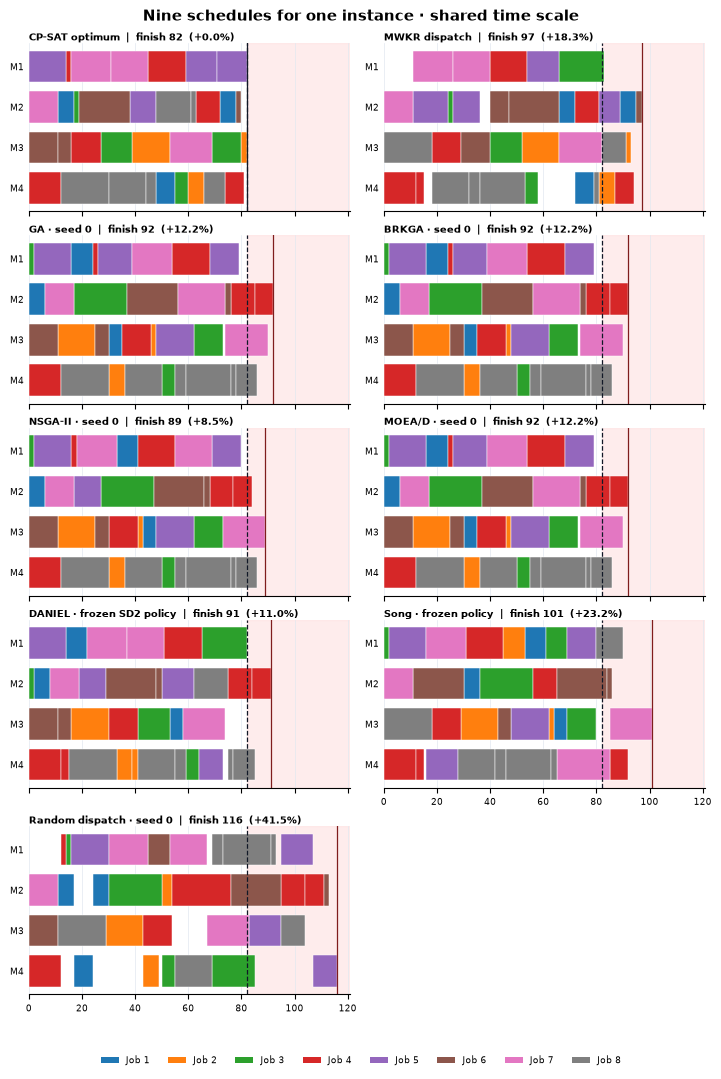

In [4]:
from baselines.evolutionary import solve, stable_seed
from baselines.multiobjective import solve as solve_multiobjective

INSTANCE = ROOT / "data/SD_original/8x4/test/test_71.fjs"
OUTPUT = ROOT / "figures/evolutionary_schedule_comparison_two_column.png"
def main():
    instance = read_fjs(INSTANCE)
    relative = INSTANCE.relative_to(ROOT / "data")
    optimal = json.loads((ROOT / "CP-SAT" / relative.with_suffix(".json")).read_text())
    if optimal["status"] != "OPTIMAL":
        raise ValueError("Selected example needs a proven CP-SAT optimum")
    ga, _, _ = solve(instance, "ga", 1000, stable_seed(INSTANCE, 0))
    brkga, _, _ = solve(instance, "brkga", 1000, stable_seed(INSTANCE, 0))
    nsga2, _, _, _, _ = solve_multiobjective(instance, "nsga2", 1000,
                                             stable_seed(INSTANCE, 0))
    moead, _, _, _, _ = solve_multiobjective(instance, "moead", 1000,
                                             stable_seed(INSTANCE, 0))
    schedule_key = INSTANCE.relative_to(ROOT).as_posix()
    saved = {}
    for method in ("daniel", "song"):
        rows = (json.loads(line) for line in
                (ROOT / "baselines/results" / f"{method}_8x4_test_schedules.jsonl")
                .read_text().splitlines())
        saved[method] = next(row for row in rows
                             if Path(row["instance"]).as_posix() == schedule_key)
    random_seed = int.from_bytes(hashlib.sha256(relative.as_posix().encode()).digest()[:8], "big")
    methods = [
        ("CP-SAT optimum", optimal),
        ("MWKR dispatch", dispatch(instance, "mwkr")),
        ("GA · seed 0", ga),
        ("BRKGA · seed 0", brkga),
        ("NSGA-II · seed 0", nsga2),
        ("MOEA/D · seed 0", moead),
        ("DANIEL · frozen SD2 policy", saved["daniel"]),
        ("Song · frozen policy", saved["song"]),
        ("Random dispatch · seed 0", dispatch(instance, "random", seed=random_seed)),
    ]
    for _, result in methods:
        validate_schedule(instance, result)
    archived = {}
    for method in ("ga", "brkga", "nsga2", "moead"):
        rows = load_rows(ROOT / "baselines/results" / f"{method}_8x4_test_seed0.csv")
        archived[method] = int(rows[schedule_key]["makespan"])
    recomputed = {"ga": ga["makespan"], "brkga": brkga["makespan"],
                  "nsga2": nsga2["makespan"], "moead": moead["makespan"]}
    output_path = OUTPUT
    if recomputed != archived:
        print("This pymoo run differs from archived seed-0 CSV makespans:",
              "archived", archived, "recomputed", recomputed)
        print("The two-column figure uses this rerun; the original figure remains separate.")
    optimum = optimal["makespan"]
    largest = max(result["makespan"] for _, result in methods)
    colors = plt.get_cmap("tab10").colors
    n_rows = (len(methods) + 1) // 2
    fig, axes = plt.subplots(n_rows, 2, figsize=(7.1, 2.025 * n_rows), sharex=True,
                             layout="constrained")
    for ax, (name, result) in zip(axes.flat, methods):
        ax.axvspan(optimum, largest + 5, color="#fee2e2", alpha=0.65, zorder=0)
        for j, job in enumerate(instance["jobs"]):
            for k, options in enumerate(job):
                machine_id, start = result["schedule"][j][k]
                duration = options[machine_id - 1]
                ax.barh(machine_id - 1, duration, left=start, height=0.78,
                        color=colors[j % len(colors)], edgecolor="white", linewidth=0.35)
        ax.axvline(optimum, color="#111827", linestyle="--", linewidth=0.9)
        ax.axvline(result["makespan"], color="#7f1d1d" if name != "CP-SAT optimum"
                   else "#111827", linewidth=0.9)
        gap = 100 * (result["makespan"] / optimum - 1)
        ax.set_title(f"{name}  |  finish {result['makespan']}  (+{gap:.1f}%)",
                     loc="left", fontsize=7.5, fontweight="bold", pad=2)
        ax.set_yticks(range(instance["n_machines"]),
                      [f"M{m + 1}" for m in range(instance["n_machines"])], fontsize=6.8)
        ax.invert_yaxis()
        ax.grid(axis="x", color="#e2e8f0", linewidth=0.5)
        ax.set_axisbelow(True)
        ax.tick_params(axis="y", length=0)
        ax.tick_params(axis="x", labelsize=6.8)
        for spine in ("top", "right", "left"):
            ax.spines[spine].set_visible(False)
    for ax in axes.flat:
        ax.set_xlim(0, largest + 5)
    for ax in list(axes.flat)[len(methods):]:
        ax.axis("off")
    for column in range(2):
        last = column + 2 * ((len(methods) - 1 - column) // 2)
        axes.flat[last].tick_params(axis="x", labelbottom=True)
    fig.suptitle("Nine schedules for one instance · shared time scale",
                 fontsize=10.5, fontweight="bold")
    fig.legend(handles=[Patch(facecolor=colors[j], label=f"Job {j + 1}")
                        for j in range(len(instance["jobs"]))],
               loc="lower center", bbox_to_anchor=(0.5, -0.055), ncol=8,
               frameon=False, fontsize=6.5)
    output_path.parent.mkdir(parents=True, exist_ok=True)
    fig.savefig(output_path, dpi=220, bbox_inches="tight", facecolor="white")
    fig.savefig(output_path.with_suffix(".pdf"), bbox_inches="tight", facecolor="white")
    print(f"Saved {output_path} and PDF")
    for name, result in methods:
        print(name, result["makespan"])

main()
